#Dataset Loading

In [10]:
from datasets import load_dataset
dataset = load_dataset("fancyzhx/ag_news")

In [11]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [12]:
print("--- Sample Data ---")
print("Text:", dataset["train"][0]["text"])
print("Label ID:", dataset["train"][0]["label"])

--- Sample Data ---
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Label ID: 2


#Dataset Splitting and Showing Each Category

In [13]:
import pandas as pd

# Map the integer labels to actual category names
label_names = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

train_data = dataset["train"].shuffle(seed=42).select(range(10000))
test_data = dataset["test"].shuffle(seed=42).select(range(2000))

# Create DataFrames
train_df = pd.DataFrame({"text": train_data["text"], "label": train_data["label"]})
test_df = pd.DataFrame({"text": test_data["text"], "label": test_data["label"]})

# Apply the mapping for a quick check
train_df["category"] = train_df["label"].map(label_names)

print(train_df["category"].value_counts())

category
Sci/Tech    2535
World       2530
Sports      2528
Business    2407
Name: count, dtype: int64


#Text Preprocessing (Tokenization, Remove Stopwords, Lemmatization)

In [17]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    # Remove punctuation/numbers
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    # Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

print("Preprocessing text")
train_df["clean_text"] = train_df["text"].apply(preprocess)
test_df["clean_text"] = test_df["text"].apply(preprocess)

print("\nExample:")
print(train_df["clean_text"][0])

Preprocessing text

Example:
bangladesh paralysed strike opposition activist brought many town city bangladesh halt day people died explosion political rally


#TF-IDF Vectorizer

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Use unigrams and bigrams (1, 2) to catch phrases like "stock market" or "white house"
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))

X_train = tfidf.fit_transform(train_df["clean_text"])
X_test = tfidf.transform(test_df["clean_text"])

y_train = train_df["label"]
y_test = test_df["label"]

print("TF-IDF Matrix shape:", X_train.shape)

TF-IDF Matrix shape: (10000, 20000)


#Logistic Regression Training

In [19]:
from sklearn.linear_model import LogisticRegression

# Scikit-Learn automatically uses Softmax for multiclass LR
lr = LogisticRegression(max_iter=1000, multi_class='multinomial')
lr.fit(X_train, y_train)

print("Model trained!")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Model trained!


#Model Evaluation

Accuracy: 0.8930

Classification Report:
              precision    recall  f1-score   support

       World       0.91      0.90      0.90       497
      Sports       0.94      0.99      0.96       483
    Business       0.89      0.82      0.85       522
    Sci/Tech       0.84      0.88      0.86       498

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



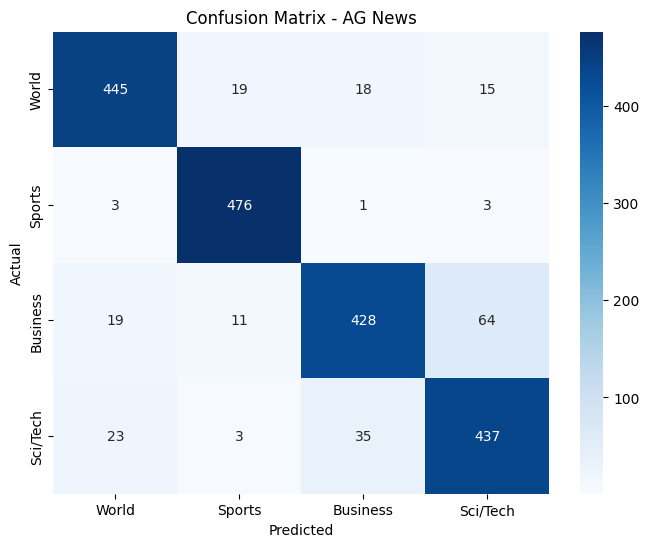

In [20]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = lr.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=list(label_names.values())))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names.values(), yticklabels=label_names.values())
plt.title("Confusion Matrix - AG News")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#Bonus-1: Visualize the most frequent words per category using bar plots

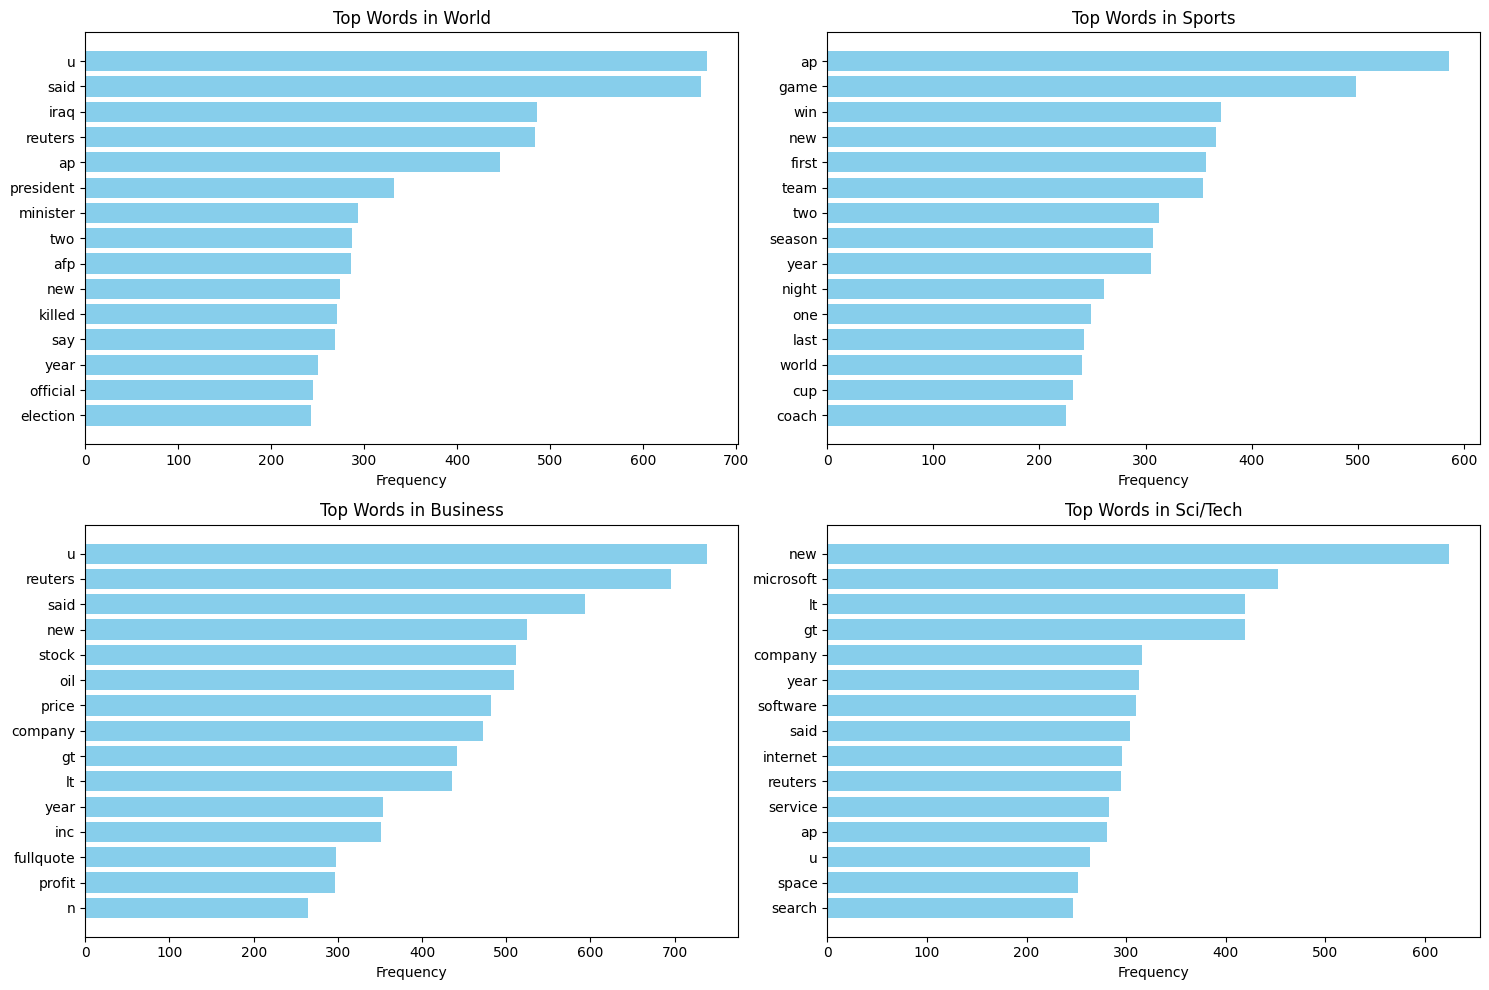

In [21]:
from collections import Counter

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, label_id in enumerate(label_names.keys()):
    # Get texts for this category
    subset = train_df[train_df["label"] == label_id]["clean_text"]
    # Count words
    all_words = " ".join(subset).split()
    top_words = Counter(all_words).most_common(15)

    # Plot
    words, counts = zip(*top_words)
    axes[i].barh(words[::-1], counts[::-1], color="skyblue")
    axes[i].set_title(f"Top Words in {label_names[label_id]}")
    axes[i].set_xlabel("Frequency")

plt.tight_layout()
plt.show()

#Neural Network Training

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# We need dense arrays for Keras (not sparse matrices), so convert the TF-IDF matrices
X_train_dense = X_train.toarray()
X_test_dense = X_test.toarray()

# Build a simple feedforward NN
nn_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_dense.shape[1],)),
    Dropout(0.3), # Prevents overfitting
    Dense(64, activation='relu'),
    Dense(4, activation='softmax') # 4 classes
])

nn_model.compile(optimizer=Adam(learning_rate=0.001),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

# Train
history = nn_model.fit(X_train_dense, y_train,
                       epochs=3,
                       batch_size=32,
                       validation_split=0.1,
                       verbose=1)

# Evaluate
loss, nn_acc = nn_model.evaluate(X_test_dense, y_test)
print(f"\nNeural Network Accuracy: {nn_acc:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.8227 - loss: 0.6209 - val_accuracy: 0.8990 - val_loss: 0.3017
Epoch 2/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.9560 - loss: 0.1399 - val_accuracy: 0.8810 - val_loss: 0.3409
Epoch 3/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.9909 - loss: 0.0338 - val_accuracy: 0.8890 - val_loss: 0.3859
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8800 - loss: 0.4194

Neural Network Accuracy: 0.8800


#Neural Network Evaluation

In [23]:
import numpy as np
from sklearn.metrics import classification_report
import pandas as pd

# Get predictions from the Neural Network model
nn_pred_probs = nn_model.predict(X_test_dense)
nn_pred = np.argmax(nn_pred_probs, axis=1)

# Print Neural Network Classification Report
print("Neural Network Classification Report:")
print(classification_report(y_test, nn_pred, target_names=list(label_names.values())))


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Neural Network Classification Report:
              precision    recall  f1-score   support

       World       0.90      0.89      0.89       497
      Sports       0.93      0.97      0.95       483
    Business       0.85      0.83      0.84       522
    Sci/Tech       0.84      0.84      0.84       498

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



In [25]:
import time
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, f1_score

#Support Vector Machine Training

In [28]:
# 1. Linear SVM
svm = LinearSVC(random_state=42)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
svm_acc = accuracy_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred, average='macro')

#Random Forest Training

In [30]:
# 2. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_dense, y_train)
rf_pred = rf.predict(X_test_dense)
rf_acc = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred, average='macro')

#XGBoost Model Training

In [31]:
# 3. XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb.fit(X_train_dense, y_train)
xgb_pred = xgb.predict(X_test_dense)
xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred, average='macro')

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:59:45] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


#LightGBM Model Training

In [32]:
# 4. LightGBM
lgbm = LGBMClassifier(random_state=42, verbose=-1)
lgbm.fit(X_train_dense, y_train)
lgbm_pred = lgbm.predict(X_test_dense)
lgbm_acc = accuracy_score(y_test, lgbm_pred)
lgbm_f1 = f1_score(y_test, lgbm_pred, average='macro')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


#All Models Comparison

In [33]:
# Recalculate LR metrics just to have them handy
lr_pred = lr.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred, average='macro')

# Create a summary DataFrame
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM", "Random Forest", "XGBoost", "LightGBM", "Neural Network (Keras)"],
    "Accuracy": [lr_acc, svm_acc, rf_acc, xgb_acc, lgbm_acc, nn_acc],
    "Macro F1-Score": [lr_f1, svm_f1, rf_f1, xgb_f1, lgbm_f1, "N/A"] # Keras f1 needs custom function
})

# Sort by Accuracy
results = results.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
print(results)

                    Model  Accuracy Macro F1-Score
0     Logistic Regression    0.8930       0.893345
1              Linear SVM    0.8925       0.893067
2  Neural Network (Keras)    0.8800            N/A
3                LightGBM    0.8745       0.875059
4                 XGBoost    0.8670       0.867661
5           Random Forest    0.8535       0.853739


In [34]:
from sklearn.metrics import f1_score

# Get the predicted class probabilities from the Neural Network
nn_pred_probs = nn_model.predict(X_test_dense)
# Convert probabilities to class labels (0, 1, 2, or 3)
nn_pred = nn_pred_probs.argmax(axis=1)

# Calculate Macro F1
nn_f1 = f1_score(y_test, nn_pred, average='macro')
print(f"Neural Network Macro F1-Score: {nn_f1:.4f}")

# Update the results table
results.loc[results["Model"] == "Neural Network (Keras)", "Macro F1-Score"] = nn_f1
print("\nUpdated Table:")
print(results)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Neural Network Macro F1-Score: 0.8806

Updated Table:
                    Model  Accuracy Macro F1-Score
0     Logistic Regression    0.8930       0.893345
1              Linear SVM    0.8925       0.893067
2  Neural Network (Keras)    0.8800       0.880579
3                LightGBM    0.8745       0.875059
4                 XGBoost    0.8670       0.867661
5           Random Forest    0.8535       0.853739
